# Email Campaign Effectiveness and Customer Value

**Data:** 64,000 customers from an e-mail marketing test (Kevin Hillstrom's MineThatData challenge). Each customer was randomly assigned to receive a Men's e-mail, a Women's e-mail, or no e-mail (about 21,300 per group). Outcomes were measured over the following two weeks.

**Questions**
1. Does an e-mail increase visits, conversions and spend, and which version works better?
2. Which customers are high value, and does the e-mail work differently for them?

| Column | Meaning |
|---|---|
| recency | Months since last purchase (1-12) |
| history / history_segment | Dollars spent in the past year |
| mens, womens | 1 if the customer bought men's / women's items in the past year |
| zip_code | Urban, Surburban (spelled this way in the data) or Rural |
| newbie | 1 if a new customer in the past 12 months |
| channel | Channel of past purchases: Phone, Web or Multichannel |
| segment | E-mail received (the experiment's treatment) |
| visit, conversion, spend | Site visit, purchase and dollars spent in the following two weeks |

## Load Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats

## Load Dataset

In [2]:
df = pd.read_csv("Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv")
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), object(4)
memory usage: 5.9+ MB


In [4]:
df.describe()

,recency,history,mens,womens,newbie,visit,conversion,spend
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250,0.146781,0.009031,1.050908
std,3.507592,256.158608,0.497393,0.497526,0.499999,0.353890,0.094604,15.036448
min,1.000000,29.990000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000,1.000000,1.000000,499.000000


In [5]:
print(f'Rows: {df.shape[0]}\nColumns: {df.shape[1]}')

Rows: 64000
Columns: 12


## 1- Data quality & Data understanding

In [6]:
df.columns

Index(['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code',
       'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend'],
      dtype='object')

In [7]:
overview = pd.DataFrame({"type": df.dtypes, "unique values": df.nunique()})
overview

,type,unique values
recency,int64,12
history_segment,object,7
history,float64,34833
mens,int64,2
womens,int64,2
zip_code,object,3
newbie,int64,2
channel,object,3
segment,object,3
visit,int64,2


In [8]:
cols = ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code',
       'newbie', 'channel', 'segment', 'visit', 'conversion']
for column in cols:
    print(f'{column}\n{df[column].unique()}')
    print(df[column].dtypes)
    print("-" * 50)

recency
[10  6  7  9  2  1  5  4  3 11 12  8]
int64
--------------------------------------------------
history_segment
['2) $100 - $200' '3) $200 - $350' '5) $500 - $750' '1) $0 - $100'
 '6) $750 - $1,000' '4) $350 - $500' '7) $1,000 +']
object
--------------------------------------------------
history
[142.44 329.08 180.65 ... 519.69 105.54 552.94]
float64
--------------------------------------------------
mens
[1 0]
int64
--------------------------------------------------
womens
[0 1]
int64
--------------------------------------------------
zip_code
['Surburban' 'Rural' 'Urban']
object
--------------------------------------------------
newbie
[0 1]
int64
--------------------------------------------------
channel
['Phone' 'Web' 'Multichannel']
object
--------------------------------------------------
segment
['Womens E-Mail' 'No E-Mail' 'Mens E-Mail']
object
--------------------------------------------------
visit
[0 1]
int64
--------------------------------------------------
conversi

In [9]:
d_change = ["recency", "mens", "womens", "newbie", "visit", "conversion"]
df[d_change] = df[d_change].astype("Int8")
df[d_change].dtypes

recency       Int8
mens          Int8
womens        Int8
newbie        Int8
visit         Int8
conversion    Int8
dtype: object

### **Missing values:** none. `isna().sum()` is 0 for all 12 columns.

In [10]:
df.isna().sum()

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

### **Duplicates:** 6,562 rows are exact duplicates. There is no customer ID, and `history` values repeat often (34,833 unique values in 64,000 rows), so identical rows may be different customers with the same attributes. We keep them

In [11]:
print(f'duplicate rows: {df.duplicated().sum()}')

duplicate rows: 6562


## 2- Customer overview

<Axes: >

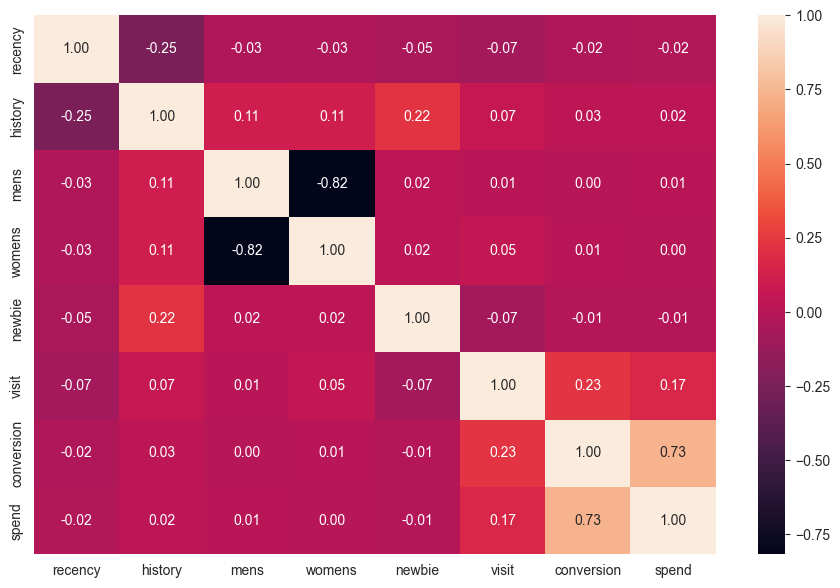

In [12]:
plt.figure(figsize=(11,7))
corr_matrix = df.corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, fmt=".2f")

In [13]:
for c in ["zip_code", "channel", "newbie", "mens", "womens", "history_segment"]:
    print(df[c].value_counts(normalize=True).sort_index().mul(100).round(1).to_string(), "\n")

zip_code
Rural        14.9
Surburban    45.0
Urban        40.1 

channel
Multichannel    12.1
Phone           43.8
Web             44.1 

newbie
0    49.8
1    50.2 

mens
0    44.9
1    55.1 

womens
0    45.0
1    55.0 

history_segment
1) $0 - $100        35.9
2) $100 - $200      22.3
3) $200 - $350      19.2
4) $350 - $500      10.0
5) $500 - $750       7.7
6) $750 - $1,000     2.9
7) $1,000 +          2.0 



### Surburban is the largest zip-code group ; web(44%) and phone(43%) are nearly most common channels; 32144 are new customers.

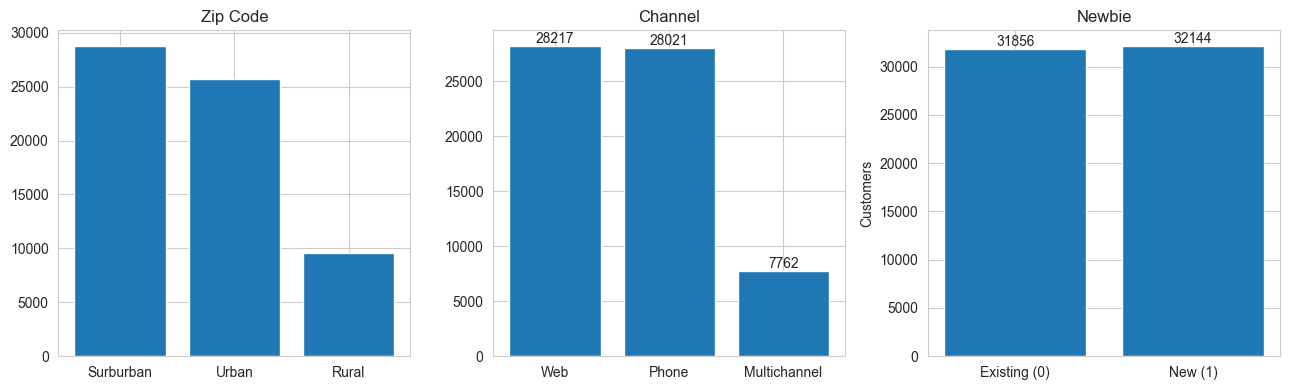

In [14]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 4))

zip_counts = df["zip_code"].value_counts()
ax1.bar(zip_counts.index, zip_counts)
ax1.set_title("Zip Code")

channel = df["channel"].value_counts()
chan = ax2.bar(channel.index, channel)
ax2.bar_label(chan)
ax2.set_title("Channel")


newbie = df["newbie"].value_counts().sort_index()
newbie.index = ["Existing (0)", "New (1)"]
new = ax3.bar(newbie.index, newbie)
ax3.bar_label(new)
ax3.set_title("Newbie")
ax3.set_ylabel("Customers")

plt.tight_layout()
plt.show()

### Most customers have purchases in last month but in months 9 and 10 purchases count increased, but we don't know why as we don't have enough information!

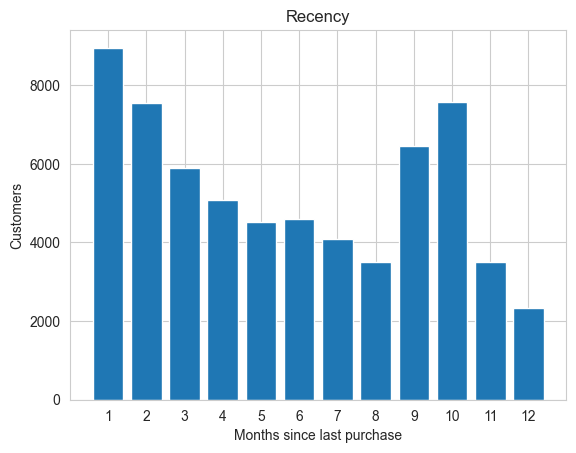

In [15]:
recency = df["recency"].value_counts().sort_index()
plt.bar(recency.index, recency)
plt.xticks(range(1,13))
plt.xlabel("Months since last purchase")
plt.ylabel("Customers")
plt.title("Recency")
plt.show()

### Past-year spend (`history`): right-skewed, 22,970 customers (35.9%) spent $0-$100 and 1,308 (2%) spent over $1,000.

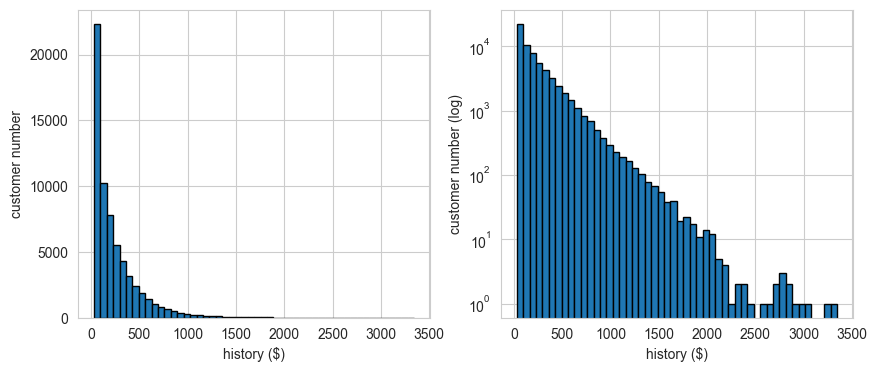

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.hist(df["history"], bins=50, edgecolor="black")
ax1.set_xlabel("history ($)"), ax1.set_ylabel("customer number")

ax2.hist(df["history"], bins=50, edgecolor="black")
ax2.set_xlabel("history ($)"), ax2.set_ylabel("customer number (log)")
ax2.set_yscale("log")

plt.show()

### Check the customers that spend more than 99% of customers

In [17]:
h = df["history"]
p99 = h.quantile(0.99)
top1 = df[h > p99]
print(f"p99 = {p99:.0f}  |  rows = {len(top1)}")

df.nlargest(15, "history")

p99 = 1219  |  rows = 640


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
4579,2,"7) $1,000 +",3345.93,1,1,Surburban,1,Phone,No E-Mail,0,0,0.0
38680,1,"7) $1,000 +",3215.97,1,1,Urban,1,Multichannel,Mens E-Mail,1,0,0.0
52860,1,"7) $1,000 +",3040.20,0,1,Urban,1,Web,Womens E-Mail,0,0,0.0
43060,1,"7) $1,000 +",3003.48,1,1,Urban,1,Phone,No E-Mail,0,0,0.0
46493,1,"7) $1,000 +",2895.11,1,1,Urban,1,Multichannel,Mens E-Mail,0,0,0.0
61447,1,"7) $1,000 +",2859.63,1,1,Urban,1,Web,Mens E-Mail,0,0,0.0
27223,7,"7) $1,000 +",2816.01,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
30038,3,"7) $1,000 +",2809.79,1,0,Surburban,1,Multichannel,Womens E-Mail,0,0,0.0
33220,1,"7) $1,000 +",2766.42,0,1,Urban,1,Multichannel,Mens E-Mail,0,0,0.0
14196,1,"7) $1,000 +",2765.98,1,0,Urban,1,Web,No E-Mail,0,0,0.0


### About 22970 customers spend between 0 to 100 dollar

history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64


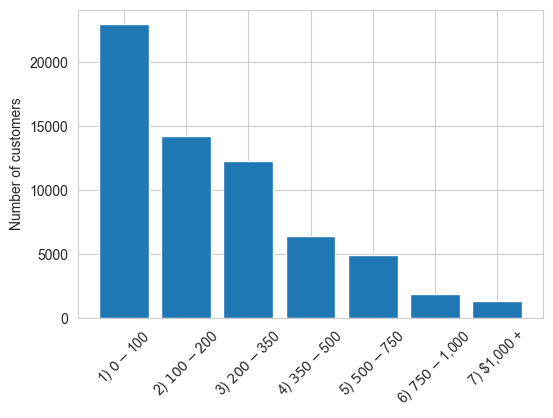

In [18]:
plt.figure(figsize=(6,4))
h_segment = df["history_segment"].value_counts()
print(h_segment)
plt.bar(h_segment.index, h_segment)
plt.ylabel("Number of customers")
plt.xticks(rotation=45)
plt.show()

#### Insights:
- **Men's Product Buyers (`mens=1, womens=0`):** 28818
- **Women's Product Buyers (`mens=0, womens=1`):** 28734
- **Dual-Category Buyers (Both) (`mens=1, womens=1`):** 6448


mens    28818
womens  28734
both  6448


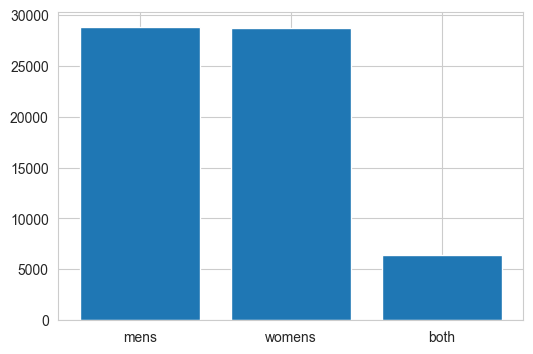

In [19]:
plt.figure(figsize=(6,4))

mens = ((df["mens"] == 1) & (df["womens"] == 0)).sum()
womens = ((df["womens"] == 1) & (df["mens"] == 0)).sum()
both = ((df["mens"]== 1) & (df["womens"] == 1)).sum()

cat = ["mens", "womens", "both"]
counts = [mens, womens, both]
print(f'mens    {mens}\nwomens  {womens}\nboth  {both}')
plt.bar(cat, counts)
plt.show()

### Emails were sent randomly

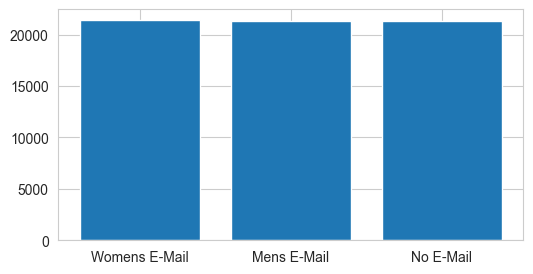

In [20]:
plt.figure(figsize=(6,3))
segment = df["segment"].value_counts()
plt.bar(segment.index, segment)
plt.show()

### Result of campaign

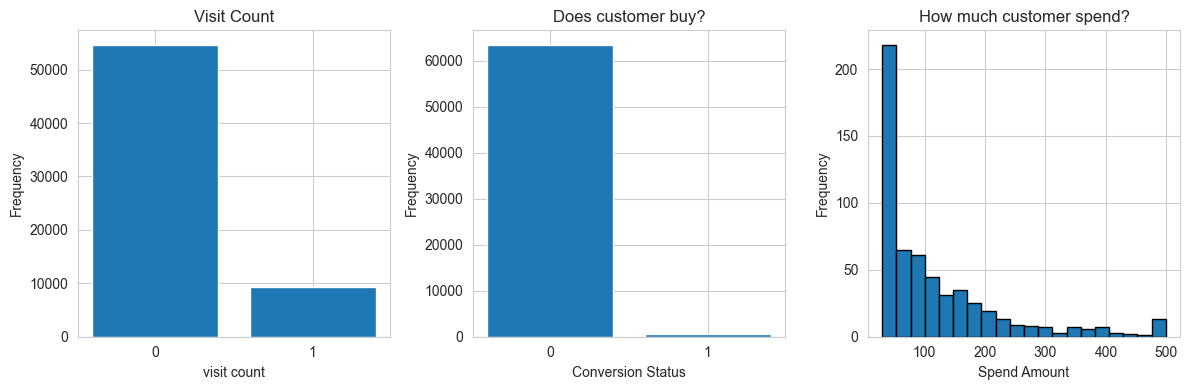

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

visit = df["visit"].value_counts().sort_index()
ax[0].bar(visit.index.astype(str), visit.values)
ax[0].set_xlabel("visit count"), ax[0].set_ylabel("Frequency")
ax[0].set_title("Visit Count")

con = df["conversion"].value_counts()
ax[1].bar(con.index.astype(str), con.values)
ax[1].set_xlabel("Conversion Status"), ax[1].set_ylabel("Frequency")
ax[1].set_title("Does customer buy?")

ax[2].hist(df.loc[df["spend"] > 0, "spend"], bins=20, edgecolor="black")
ax[2].set_xlabel("Spend Amount"), ax[2].set_ylabel("Frequency")
ax[2].set_title("How much customer spend?")

plt.tight_layout()
plt.show()

In [22]:
df["spend"].mean().round(3)

1.051

## 3- Customer value analysis
### - Who are the company’s most valuable customers?

In [23]:
df["customer_value"] = pd.qcut(df["history"], q=3, labels=["low", "medium", "high"])

In [24]:
df["customer_value"].value_counts()

customer_value
low       21335
medium    21333
high      21332
Name: count, dtype: int64

In [25]:
df.groupby("customer_value", observed=False)["history"].agg(["count", "mean","median", "min", "max"]).round(2)

,count,mean,median,min,max
customer_value,,,,,
low,21335,48.29,41.26,29.99,91.14
medium,21333,162.82,158.12,91.16,254.61
high,21332,515.18,428.15,254.62,3345.93


### Did the customers who purchased more in the past behave differently in the next two weeks?

In [26]:
r = df.groupby("customer_value", observed=False )[["visit", "conversion", "spend"]].mean()
r

,visit,conversion,spend
customer_value,,,
low,0.122897,0.007171,0.911008
medium,0.135752,0.007359,0.834067
high,0.181699,0.012563,1.407679


### Was the email more effective for high-value customers than for low-value customers?

In [27]:
c_value = df.groupby(["customer_value", "segment"], observed=False)[["visit", "conversion", "spend"]].mean()
c_value

visit  conversion     spend
customer_value segment                                      
low            Mens E-Mail    0.152289    0.009213  1.064266
               No E-Mail      0.083722    0.004243  0.508642
               Womens E-Mail  0.132254    0.008028  1.157092
medium         Mens E-Mail    0.172233    0.010614  1.220415
               No E-Mail      0.098838     0.00462  0.509195
               Womens E-Mail  0.136581    0.006878  0.776604
high           Mens E-Mail    0.224106    0.017804  1.987260
               No E-Mail      0.135928    0.008319  0.941136
               Womens E-Mail  0.185118    0.011587  1.296975

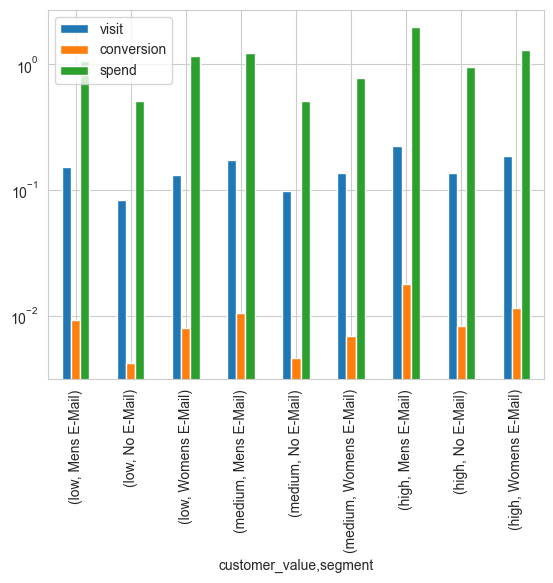

In [28]:
c_value.plot(kind= "bar", log =True)
plt.show()

## 4- Recency analysis
### Recency (time spent from the customer last purchase)
### How is recency related to customer response and spending?

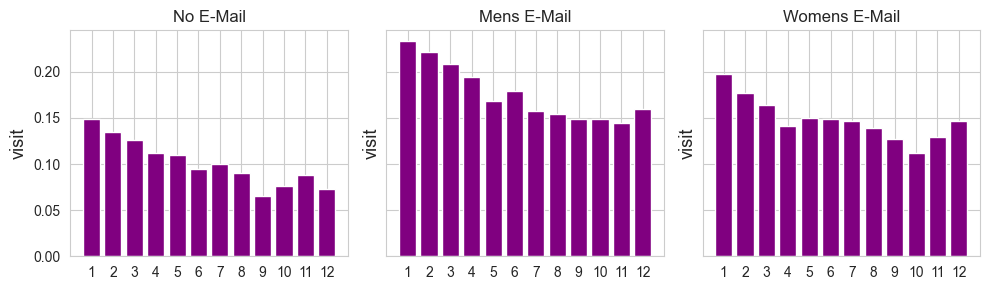

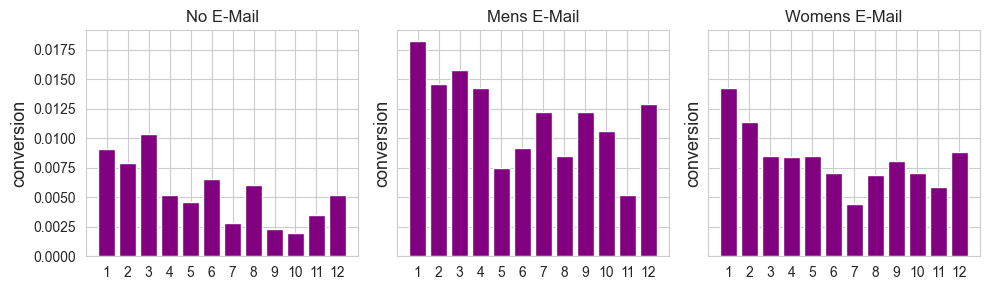

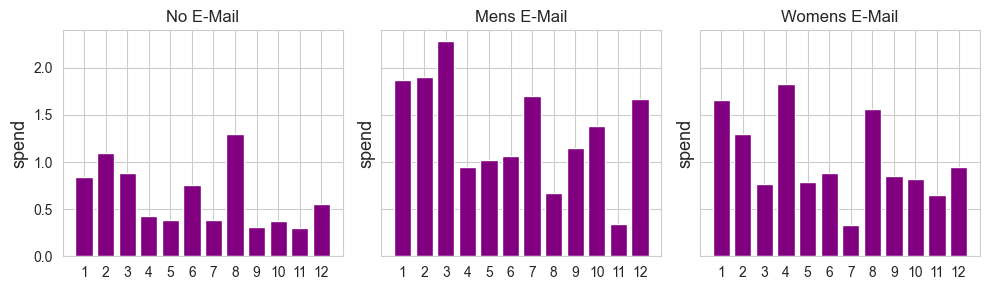

In [29]:
def bar_seg(df, target):
    segments = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
    fig, axes = plt.subplots(1,3, figsize =(10,3), sharex=True, sharey=True)
    for i,seg in enumerate(segments):
        df_seg = df[df["segment"] == seg]
        x = df_seg.groupby("recency")[target].mean()
        ax = axes[i]
        ax.bar(x.index.astype(str), x.values, color="purple")
        ax.set_title(f"{seg}")
        ax.set_ylabel(target,fontsize=13)
    plt.tight_layout()
    plt.show()

bar_seg(df, "visit")
bar_seg(df, "conversion")
bar_seg(df, "spend")

### Is recency a good metric for targeting?

## 5- New vs Existing Customer
### What is the difference between the behavior of new and existing customers?

### Should the company use the same marketing strategy for new and old customers?

### Existing customers generally had higher conversion rates and average spending than new customers in the No E-Mail and Mens E-Mail groups. However, in the Womens E-Mail group, new customers had slightly higher conversion rates and average spending. This suggests that customer response varies by email campaign type.

In [30]:
x = df.groupby(["segment","newbie"])[["history","visit", "conversion", "spend"]].mean().round(4)
x

history   visit  conversion   spend
segment       newbie                                      
Mens E-Mail   0       184.1000  0.2116      0.0139  1.5133
              1       301.2146  0.1541      0.0111  1.3325
No E-Mail     0       184.1985  0.1337      0.0077  0.9354
              1       297.1216  0.0788      0.0037  0.3724
Womens E-Mail 0       185.6007  0.1739      0.0087  1.0493
              1       298.7373  0.1292       0.009  1.1047

## 6- Channel Analysis
### Which channel has more valuable customers?

### Multichannel customers had much higher historical spending than Phone and Web customers. They also showed the highest conversion rates and average spending in both email-treatment groups. However, historical spending reflects past customer value and does not necessarily measure the incremental effect of the email campaign.

In [31]:
ch = df.groupby(["segment", "channel"])[["history","visit", "conversion", "spend"]].mean().round(4)
ch

history   visit  conversion   spend
segment       channel                                           
Mens E-Mail   Multichannel  528.8701  0.2115      0.0171  1.8249
              Phone         204.4096  0.1628      0.0108  1.2085
              Web           202.5777  0.1944       0.013  1.5218
No E-Mail     Multichannel  516.5902  0.1285      0.0069  0.6157
              Phone         200.4702  0.0872      0.0054  0.6445
              Web           204.4411  0.1189      0.0058  0.6714
Womens E-Mail Multichannel  517.5028  0.1756       0.014  1.7733
              Phone         203.5466  0.1318      0.0071  0.8769
              Web           206.1323  0.1645      0.0092  1.0877

## 7- Geographic Analysis
### Is customer behavior different in different regions?

### Rural customers had the highest conversion rates in all three groups. However, the increase in conversion rate from the No E-Mail group to the Mens E-Mail group was larger in Suburban areas than in Rural or Urban areas. This suggests that the campaign's observed impact may vary by region

In [32]:
ge = df.groupby(["segment", "zip_code"])[["history","visit", "conversion", "spend"]].mean().round(4)
ge

history   visit  conversion   spend
segment       zip_code                                       
Mens E-Mail   Rural      238.2246   0.227      0.0136  1.5226
              Surburban  241.2688  0.1734      0.0124  1.4733
              Urban      246.3212  0.1765      0.0123  1.3285
No E-Mail     Rural      250.4249  0.1536      0.0083  0.7671
              Surburban  238.9172   0.099       0.005  0.6694
              Urban      239.5907  0.0968      0.0056  0.5920
Womens E-Mail Rural      240.1024  0.1826      0.0116  1.2820
              Surburban  241.2887  0.1479      0.0076  0.8466
              Urban      244.8492  0.1438      0.0092  1.2611

## 8- Customer Funnel
### How is campaign funnel?

**Campaign funnel.** The funnel has three steps: customers → website visitors → buyers. Both e-mails increase visits clearly: the visit rate is 10.6% without an e-mail, 15.1% with the Women's e-mail and 18.3% with the Men's e-mail. The conversion rate per customer follows the same order (0.57%, 0.88% and 1.25%). The step from visit to purchase changes much less (5.4%, 5.8% and 6.9%), so most of the e-mail effect happens before the purchase, when the e-mail brings customers to the website. The visit-to-purchase rate is measured only among customers who visited after the e-mail, so it should be read as a description, not as a pure effect of the e-mail.

In [33]:
funnel = df.groupby("segment").agg(
    customers = ("visit", "count"),
    visit = ("visit", "sum"),
    conversion = ("conversion", "sum")
)
funnel

,customers,visit,conversion
segment,,,
Mens E-Mail,21307,3894,267
No E-Mail,21306,2262,122
Womens E-Mail,21387,3238,189


In [34]:
funnel["visit_rate"] = (funnel["visit"] / funnel["customers"] )
funnel["conversion_rate"] = (funnel["conversion"] / funnel["customers"])
funnel["visit_to_purchase"] = (funnel["conversion"] / funnel["visit"])

In [35]:
funnel.style.format({"visit_rate": "{:.2%}",
                 "conversion_rate": "{:.2%}",
                 "visit_to_purchase": "{:.2%}"})

,customers,visit,conversion,visit_rate,conversion_rate,visit_to_purchase
segment,,,,,,
Mens E-Mail,21307,3894,267,18.28%,1.25%,6.86%
No E-Mail,21306,2262,122,10.62%,0.57%,5.39%
Womens E-Mail,21387,3238,189,15.14%,0.88%,5.84%


## 9- Campaign performance
### Which campaign had the best raw performance?

### Men's E-Mail had the strongest raw performance across visit rate, conversion rate, and revenue per customer.

In [36]:
per = df.groupby("segment").agg(
    number_of_customers = ("visit", "size"),
    visit = ("visit", "sum"),
    conversion = ("conversion", "sum"),
    average_spend = ("spend", "mean"),
    total_spend = ("spend", "sum")
)
per

,number_of_customers,visit,conversion,average_spend,total_spend
segment,,,,,
Mens E-Mail,21307,3894,267,1.422617,30311.69
No E-Mail,21306,2262,122,0.652789,13908.33
Womens E-Mail,21387,3238,189,1.077202,23038.11


In [37]:
visit_rate = (per["visit"] / per["number_of_customers"])
conversion_rate = (per["conversion"] / per["number_of_customers"])
revenue_per_customer = per["total_spend"] / per["number_of_customers"]

print(visit_rate.round(4) * 100)
print(conversion_rate.round(4) * 100)
print(revenue_per_customer.round(4))

segment
Mens E-Mail      18.28
No E-Mail        10.62
Womens E-Mail    15.14
dtype: Float64
segment
Mens E-Mail      1.25
No E-Mail        0.57
Womens E-Mail    0.88
dtype: Float64
segment
Mens E-Mail      1.4226
No E-Mail        0.6528
Womens E-Mail    1.0772
dtype: Float64


## 10- A/B Testing
### Men's Email vs No Email
### Did the Men's Email increase conversions?

**Hypotheses** (α = 0.05, two-sided)
- H0: p_men = p_control — the conversion rate is the same in both groups
- H1: p_men ≠ p_control — the conversion rates are different

In [38]:
mens = df.loc[df["segment"] == "Mens E-Mail", "conversion"].astype(int)
ctrl = df.loc[df["segment"] == "No E-Mail", "conversion"].astype(int)

In [39]:
n_men = len(mens)
n_ctrl = len(ctrl)

buyers_men = mens.sum()
buyers_ctrl = ctrl.sum()

rate_men = mens.mean()
rate_ctrl = ctrl.mean()

In [40]:
from statsmodels.stats.proportion import proportions_ztest

z_stat, p_value = proportions_ztest(
    count=[buyers_men, buyers_ctrl],
    nobs=[n_men, n_ctrl],
    alternative="two-sided")

In [41]:
alpha = 0.05

print(f"Men's Email Conversion: {rate_men:.2%}")
print(f"Control Conversion: {rate_ctrl:.2%}")
print(f"Z-statistic: {z_stat:.3f}")
print(f"P-value: {p_value:.5f}")

if p_value < alpha:
    print("Statistically significant difference.")
else:
    print("No statistically significant difference.")

Men's Email Conversion: 1.25%
Control Conversion: 0.57%
Z-statistic: 7.385
P-value: 0.00000
Statistically significant difference.


## 11- A/B Testing
### Women's Email vs No Email
### Did the women's Email increase conversions?

**Hypotheses** (α = 0.05, two-sided)
- H0: p_women = p_control — the conversion rate is the same in both groups
- H1: p_women ≠ p_control — the conversion rates are different

In [42]:
womens = df.loc[df["segment"] == "Womens E-Mail", "conversion"].astype(int)
ctrl_w = df.loc[df["segment"]== "No E-Mail", "conversion"].astype(int)

In [43]:
n_women = len(womens)
n_ctrl_w = len(ctrl_w)

buyers_women = womens.sum()
buyers_ctrl_w = ctrl_w.sum()

rate_women = womens.mean()
rate_ctrl_w = ctrl_w.mean()

In [44]:
z_stat, p_value = proportions_ztest(
    count=[buyers_women, buyers_ctrl_w],
    nobs=[n_women, n_ctrl_w],
    alternative="two-sided")

In [45]:
alpha = 0.05

print(f"Womens Email Conversion: {rate_women:.2%}")
print(f"Control Conversion: {rate_ctrl_w:.2%}")
print(f"Z-statistic: {z_stat:.3f}")
print(f"P-value: {p_value:.5f}")

if p_value < alpha:
    print("Statistically significant difference.")
else:
    print("No statistically significant difference.")

Womens Email Conversion: 0.88%
Control Conversion: 0.57%
Z-statistic: 3.780
P-value: 0.00016
Statistically significant difference.


## 12- Statistical vs Business Significance

### Is the statistical result important for the business as well?

## 13- Revenue Analysis

### Did the campaign only increase conversions, or did it also drive an increase in revenue?

### Is it possible for a campaign to increase conversions but not produce much revenue?

In [46]:
c = df.groupby("segment").agg(
    customers=("spend", "size"),
    buyers=("conversion", "sum"),
    total_revenue=("spend", "sum"),
)
c["conversion_rate"] = c["buyers"] / c["customers"]
c["revenue_per_customer"] = c["total_revenue"] / c["customers"]
c["spend_per_buyer"] = c["total_revenue"] / c["buyers"]

c["median_spend_per_buyer"] = df[df["conversion"] == 1].groupby("segment")["spend"].median()
c.round(3)

,customers,buyers,total_revenue,conversion_rate,revenue_per_customer,spend_per_buyer,median_spend_per_buyer
segment,,,,,,,
Mens E-Mail,21307,267,30311.69,0.013,1.423,113.527,66.980
No E-Mail,21306,122,13908.33,0.006,0.653,114.003,88.365
Womens E-Mail,21387,189,23038.11,0.009,1.077,121.895,94.710


## 14- Customer Targeting

### For which customer segment did the campaign perform better?